# [16.11] Dataset Cartography

## Introduction

**Can a model's learning history tell you which training examples to keep?**

Suppose two handwritten digits both receive the correct answer after training.
One was recognized almost immediately. The other spent ten epochs looking like
a different digit before the model learned it. Final accuracy treats them alike.
A **data map** puts their learning histories back into the picture.

In these exercises you will make this map yourself, follow particular images
across training, and use the map to choose training data. Then you will train
fresh models to find out whether your choices helped. You will also inject a
known set of label errors and investigate how reliably the map finds them.

### Content & Learning Objectives

1. **Coordinates from learning histories.** Track stable example IDs, compute
   assigned-label confidence, temporal variability and correctness, and derive
   the curved boundary of a data map.
2. **Map a real training run.** Implement the logging loop; compare seeds,
   architectures, logging times, label errors and training windows. Inspect the
   images behind the points instead of treating region names as ground truth.
3. **Choose data, then retrain.** Compare map regions with uniform and
   class-matched random subsets; separate data-selection effects from class
   coverage and optimizer-update budgets.

You should be comfortable with minibatch training and PyTorch autograd from
original ARENA [0.3 Optimization](../../../chapter0_fundamentals/exercises/part3_optimization/0.3_Optimization_exercises.ipynb).
[16.9 Influence and TracIn](../part9_influence_and_tracin/README.md) and
[16.10 Datamodels](../part10_datamodels/README.md) ask related questions about
training data. Here we begin with the history of one training run rather than
an optimum derivative or a regression across many subsets.

Allow **4–6 hours** for the implementations, explanations and experiments.
The complete reference experiment runs on CPU. Its speed comes from training
small independent networks together, with no shared parameters or cached fits.
The first run downloads a small public dataset; subsequent runs check the same
source bytes locally.

## Setup


In [1]:
from pathlib import Path
from types import SimpleNamespace
import hashlib
import json
import math
import os
import sys
import tempfile

import numpy as np
import torch
from torch import Tensor
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "chapter16_shapley_attribution_baselines").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from chapter16_shapley_attribution_baselines.exercises.part11_dataset_cartography import (
    cartography_methods_tests as tests,
)
from chapter16_shapley_attribution_baselines.exercises.part11_dataset_cartography.cartography_data import (
    load_training,
    load_evaluation,
)
from chapter16_shapley_attribution_baselines.exercises.part11_dataset_cartography.run_native import (
    validate_freeze,
    reference_checks,
    summarize,
)

torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
OUTPUT = Path(os.environ.get("ARENA_CARTOGRAPHY_OUTPUT_DIRECTORY", "/tmp/arena16_11_cartography"))
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def show_figure(figure, name):
    figure.savefig(OUTPUT / f"{name}.png", dpi=145, bbox_inches="tight")
    plt.show()
    plt.close(figure)


validate_freeze()
train = load_training()
print(f"Training pool: {len(train['ids'])} images; 300 per digit; 300 known injected label errors.")


Training pool: 3000 images; 300 per digit; 300 known injected label errors.


### A label is an assertion you can inspect

The source contains 8×8 images of ten handwritten digits. We use 3,000 images
from the original training file, chosen before fitting any model. The remaining
823 images form a same-source holdout. The original 1,797-image test file comes
from separate writers. No exact pixel duplicates cross either training/holdout
boundary. Individual writer IDs are unavailable, so the same-source holdout is
not guaranteed to contain different writers.

For the noise experiment, we change exactly 30 labels per class to the next
class modulo ten. The original images stay fixed. This is deliberately created
noise, with a known answer to the diagnosis exercise. It does not establish that
an untouched source example has an annotation error.

Look at the images below. For each changed label, predict what will happen to
the probability of its **assigned** label during training.


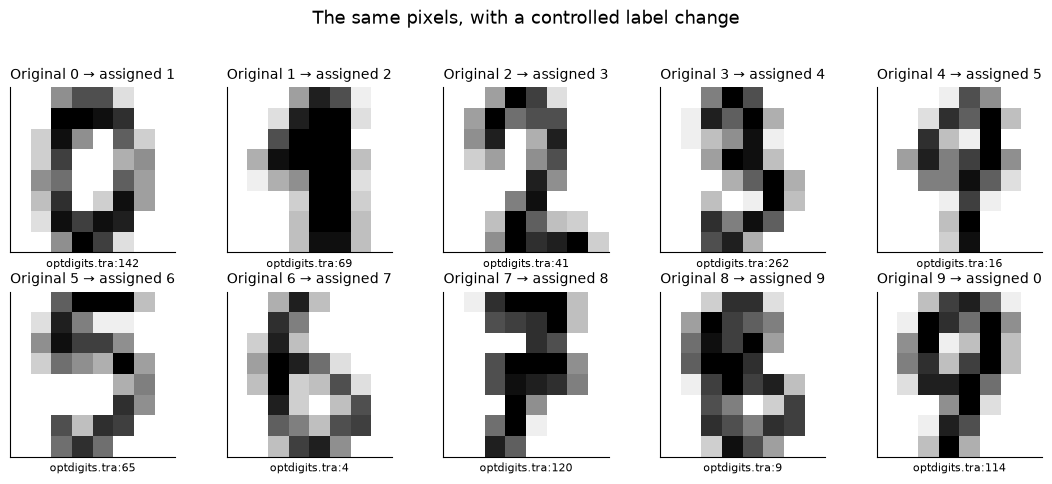

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
for position, ax in enumerate(axes.flat):
    indices = torch.where((train["y"] == position) & train["changed"])[0]
    index = int(indices[0])
    ax.imshow(train["x"][index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"Original {position} → assigned {int(train['noisy_y'][index])}", fontsize=10)
    ax.set_xlabel(train["ids"][index], fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("The same pixels, with a controlled label change", y=1.03)
fig.tight_layout()
show_figure(fig, "cartography_images")


## 1️⃣ Turn a learning history into coordinates

For example $i$, let $p_{e,i}$ be the probability assigned to its dataset label
at epoch $e$. The label may be wrong. This is **not** the maximum probability
among classes. A network that confidently calls a mislabeled “3” an “8” can
have a high maximum probability and a very low assigned-label probability.

Our three coordinates are

$$\mu_i=\frac{1}{E}\sum_{e=1}^E p_{e,i},\qquad
\sigma_i=\sqrt{\frac{1}{E}\sum_{e=1}^E(p_{e,i}-\mu_i)^2},\qquad
c_i=\frac{1}{E}\sum_{e=1}^E\mathbf{1}[\arg\max_k z_{e,i,k}=y_i].$$

Confidence is $\mu$, variability is $\sigma$, and correctness is $c$. The data
map places variability horizontally and confidence vertically; color represents
correctness. These summaries discard temporal order. A steadily improving
example can have the same coordinates as an example that repeatedly flips.

Before computing them, we need to make sure that row 17 at one epoch still
means the same image at the next epoch. Minibatch shuffling makes this easy to
get wrong without producing an obvious tensor-shape error.


### Exercise - restore example identity after shuffling

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10–15 minutes on this exercise.
> ```

`logits` has shape `[models, examples, classes]`. Each corresponding row of
`visited_ids` is a permutation of canonical IDs `0, ..., N-1`. Return logits in
canonical order. Reject duplicates, missing IDs and shape mismatches. Different
models may visit examples in different orders.


In [ ]:
def align_epoch(logits: Tensor, visited_ids: Tensor) -> Tensor:
    """Restore B × N × C logits to canonical integer IDs 0 through N-1."""
    raise NotImplementedError()


tests.test_align_epoch(align_epoch)


<details>
<summary>Help - where should I start?</summary>

Sort the IDs, check that the sorted values equal `arange(N)`, then use the
sorting indices to gather the class vectors. Sorting the logits themselves
would destroy the labels' meaning.

</details>

<details>
<summary>Expected output</summary>

The shuffled example with canonical ID 2 returns to row 2 for both models.
Duplicate or missing visits raise an informative error. A passing shape check
alone would not catch the identity bug.

</details>

<details><summary>Solution</summary>

```python
def align_epoch(logits: Tensor, visited_ids: Tensor) -> Tensor:
    """Restore B × N × C logits to canonical integer IDs 0 through N-1."""
    if logits.ndim != 3 or visited_ids.shape != logits.shape[:2]:
        raise ValueError("Expected one visited ID per model and example.")
    expected = torch.arange(logits.shape[1], device=visited_ids.device)
    if not torch.equal(visited_ids.sort(dim=1).values, expected.expand_as(visited_ids)):
        raise ValueError(
            "Every epoch must visit each ID exactly once; check missing/duplicate IDs."
        )
    return logits.gather(1, visited_ids.argsort(dim=1)[..., None].expand_as(logits))
```

</details>


### Exercise - compute confidence, variability and correctness

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 15–20 minutes on this exercise.
> ```

Implement the assigned-label probability and the three map statistics.
The full logit tensor has shape `[epochs, models, examples, classes]`; labels
have shape `[models, examples]`. Preserve model and example axes. Use population
standard deviation and the first class index for an argmax tie.


In [ ]:
def gold_probabilities(logits: Tensor, labels: Tensor) -> Tensor:
    """Gather the assigned label, preserving any leading epoch dimension."""
    raise NotImplementedError()


tests.test_gold_probabilities(gold_probabilities)


def training_statistics(logits: Tensor, labels: Tensor) -> dict[str, Tensor]:
    """Reduce E × B × N × C over epochs only; variability uses population SD."""
    raise NotImplementedError()


tests.test_training_statistics(training_statistics)


<details>
<summary>Help - where should I start?</summary>

Apply softmax over the last axis, gather labels, then reduce over axis zero.
PyTorch's default standard-deviation correction is one; the paper divides by
`E`, so use `correction=0`. A one-epoch map must have variability zero.

</details>

<details>
<summary>Expected output</summary>

The history `[0.1, 0.5, 0.9]` has confidence 0.5 and variability about 0.327.
A constant history has zero variability. The tests distinguish assigned-label
probability from top-class probability and check ties and a one-epoch window.

</details>

<details><summary>Solution</summary>

```python
def gold_probabilities(logits: Tensor, labels: Tensor) -> Tensor:
    """Gather the assigned label, preserving any leading epoch dimension."""
    probabilities = logits.softmax(dim=-1)
    indices = labels.expand(logits.shape[:-1]).unsqueeze(-1)
    return probabilities.gather(-1, indices).squeeze(-1)


def training_statistics(logits: Tensor, labels: Tensor) -> dict[str, Tensor]:
    """Reduce E × B × N × C over epochs only; variability uses population SD."""
    if logits.ndim != 4 or logits.shape[0] == 0 or labels.shape != logits.shape[1:3]:
        raise ValueError("Use nonempty epoch/model/example/class logits and model/example labels.")
    probabilities = gold_probabilities(logits, labels)
    return dict(
        confidence=probabilities.mean(dim=0),
        variability=probabilities.std(dim=0, correction=0),
        correctness=(logits.argmax(dim=-1) == labels).float().mean(dim=0),
    )
```

</details>


### Why does the map have a curved edge?

For any $p\in[0,1]$, $p^2\le p$. Apply this inequality to every epoch and take
the mean. What upper bound does it give on $\sigma^2$? What kinds of learning
histories approach the boundary?

<details><summary>Help - expand the variance</summary>

Write $\sigma^2=E[p^2]-E[p]^2$. Here $E[\cdot]$ is an average over the recorded
epochs, not an expectation over independently trained models.

</details>

<details><summary>Solution - variance bound</summary>

$$\sigma^2\le\mu-\mu^2=\mu(1-\mu).$$

Equality requires probabilities to be zero or one at every recorded epoch.
The boundary is therefore a mathematical property of bounded probabilities;
it is not evidence for three natural species of training examples. In particular,
large variability requires confidence away from both zero and one.

</details>

### Try It Yourself - change a learning history

Change `history` below. Try a smooth rise, alternating extremes, and a constant
sequence. Predict the point before running the cell. Then reverse or permute
exactly the same values: the map point stays fixed even though the story changes.
The dashed constant history is the control. These are probability fixtures,
not outputs from the digit classifier.


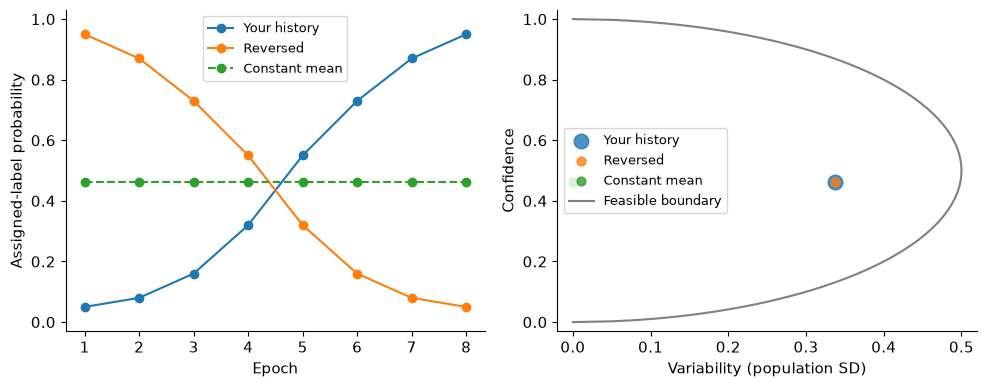

In [5]:
history = torch.tensor([0.05, 0.08, 0.16, 0.32, 0.55, 0.73, 0.87, 0.95])
assert (
    (history > 0) & (history < 1)
).all(), "Keep fixture probabilities strictly between zero and one."
curves = {
    "Your history": history,
    "Reversed": history.flip(0),
    "Constant mean": history.mean().expand_as(history),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, values in curves.items():
    logits = torch.stack([values.log(), (1 - values).log()], dim=-1)[:, None, None]
    point = training_statistics(logits, torch.zeros(1, 1, dtype=torch.long))
    axes[0].plot(
        range(1, len(values) + 1), values, "o--" if name == "Constant mean" else "o-", label=name
    )
    axes[1].scatter(
        point["variability"],
        point["confidence"],
        s=110 if name == "Your history" else 40,
        label=name,
        alpha=0.8,
    )
mu = torch.linspace(0, 1, 401)
axes[1].plot(torch.sqrt(mu * (1 - mu)), mu, color="gray", label="Feasible boundary")
axes[0].set(xlabel="Epoch", ylabel="Assigned-label probability", ylim=(-0.03, 1.03))
axes[1].set(
    xlabel="Variability (population SD)",
    ylabel="Confidence",
    xlim=(-0.02, 0.52),
    ylim=(-0.03, 1.03),
)
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
show_figure(fig, "cartography_trajectory_play")


## 2️⃣ Make the map from actual training

We will train a 64 → 64 → 10 ReLU network with ordinary minibatch SGD. Each
independent run has its own parameters, random generator, initialization and
epoch permutation. The extra leading dimension below simply schedules several
runs together. There is no ensembling of predictions during training.

The optimizer uses learning rate 0.05, momentum 0.9 and weight decay 0.0001 on
all parameters, including biases. We train for 30 epochs with batches of 128,
including the final partial batch. There is no dropout, augmentation, early
stopping, tuned checkpoint or learned input normalization.

The initialization helper below provides the small architecture's parameters.
The two central operations—forward computation and training/logging—are yours
to implement. A width of zero selects the linear comparison model.


In [6]:
def initialize_parameters(features, classes, width, generators):
    """Small architecture setup; independent generators also supply batch orders."""
    draws = []
    for generator in generators:
        if width:
            item = dict(
                w1=torch.randn(features, width, generator=generator) * math.sqrt(2 / features),
                b1=torch.zeros(1, width),
                w2=torch.randn(width, classes, generator=generator) / math.sqrt(width),
                b2=torch.zeros(1, classes),
            )
        else:
            item = dict(
                w=torch.randn(features, classes, generator=generator) / math.sqrt(features),
                b=torch.zeros(1, classes),
            )
        draws.append(item)
    return {name: torch.stack([item[name] for item in draws]).requires_grad_() for name in draws[0]}


### Exercise - evaluate independent networks together

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10–15 minutes on this exercise.
> ```

Apply each parameter set to its corresponding input tensor. Inputs have shape
`[B, N, D]`, hidden weights `[B, D, H]`, hidden biases `[B, 1, H]`, output weights
`[B, H, C]`, and output biases `[B, 1, C]`. The linear case has keys `w` and `b`.
Return `[B, N, C]` logits. Keep the model axis intact.


In [ ]:
def batched_logits(parameters: dict[str, Tensor], x: Tensor) -> Tensor:
    """Apply independent linear or one-hidden-layer networks along model axis B."""
    raise NotImplementedError()


tests.test_batched_logits(batched_logits)


<details>
<summary>Help - where should I start?</summary>

Matrix multiplication handles the leading model dimension. ReLU belongs
between the two linear operations. A model's output must not depend on another
model's weights or examples.

</details>

<details>
<summary>Expected output</summary>

Both architectures agree with an independent NumPy loop for each model.
No averaging over models occurs.

</details>

<details><summary>Solution</summary>

```python
def batched_logits(parameters: dict[str, Tensor], x: Tensor) -> Tensor:
    """Apply independent linear or one-hidden-layer networks along model axis B."""
    if "w1" in parameters:
        hidden = (x @ parameters["w1"] + parameters["b1"]).relu()
        return hidden @ parameters["w2"] + parameters["b2"]
    return x @ parameters["w"] + parameters["b"]
```

</details>


### Two reasonable logging times can yield different maps

The paper's equation uses the parameters at the **end of an epoch**. The released
training loop instead saves an example's logits when its minibatch is visited,
before that minibatch's update. The two records answer different questions:

- **Visited minibatch:** how did the model respond when it trained on this example?
- **Epoch end:** how does one common checkpoint respond to every example?

We retain both. The main results use epoch-end snapshots; we directly measure
how much the other convention changes the map. This distinction matters most
when substantial learning happens during the first epoch.

A common bug in accelerated training is to take a mean over models as well as
examples. That divides each network's gradient by the number of scheduled runs.
Use the mean loss **within each model**, then sum those independent losses before
calling autograd. The sum introduces no cross-model gradient paths.


### Exercise - train and record both learning histories

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 35–45 minutes on this exercise.
> ```

Train fresh models and return final parameters, both `[E, B, N, C]` logit
traces, `[E, B]` epoch-end losses, seed metadata and the number of updates per
model. Reuse the initializer and forward function above. Each epoch must visit
every training example exactly once. Record visited logits before updating,
then realign them by canonical ID. Record the second trace after the full epoch.
For `record=False`, retain final parameters and epoch losses but return empty
logit traces; this saves memory for the later pruning experiments.


In [ ]:
def train_ensemble(
    x: Tensor,
    labels: Tensor,
    seeds: list[int],
    width: int = 64,
    epochs: int = 30,
    batch_size: int = 128,
    lr: float = 0.05,
    momentum: float = 0.9,
    weight_decay: float = 0.0001,
    classes: int = 10,
    record: bool = True,
) -> dict:
    """Fresh SGD runs, with pre-update visits and epoch-end snapshots aligned by ID."""
    raise NotImplementedError()


tests.test_train_ensemble(train_ensemble)


<details>
<summary>Help - where should I start?</summary>

Create one generator per run and draw its weights before its permutations.
For momentum, the first buffer is the gradient including weight decay; a zero
buffer followed by `buffer = momentum * buffer + gradient` gives this behavior.
Update parameters under `torch.no_grad()`. Clone recorded tensors so later
updates cannot alter earlier observations. Check the final partial minibatch.

</details>

<details>
<summary>Expected output</summary>

An independent ordinary `torch.nn` + `torch.optim.SGD` loop matches both
architectures and both seeds on a small fixture, including every visited logit,
epoch-end logit, final parameter and loss. The fixture has nine updates, not six.
The two logging conventions produce different traces.

</details>

<details><summary>Solution</summary>

```python
def train_ensemble(
    x: Tensor,
    labels: Tensor,
    seeds: list[int],
    width: int = 64,
    epochs: int = 30,
    batch_size: int = 128,
    lr: float = 0.05,
    momentum: float = 0.9,
    weight_decay: float = 0.0001,
    classes: int = 10,
    record: bool = True,
) -> dict:
    """Fresh SGD runs, with pre-update visits and epoch-end snapshots aligned by ID."""
    if x.ndim != 3 or labels.shape != x.shape[:2] or len(seeds) != x.shape[0]:
        raise ValueError("Provide B × N × D inputs, B × N labels and B run seeds.")
    if min(epochs, batch_size, x.shape[1]) < 1:
        raise ValueError("Epoch, minibatch and dataset sizes must be positive.")
    generators = [torch.Generator().manual_seed(seed) for seed in seeds]
    parameters = initialize_parameters(x.shape[-1], classes, width, generators)
    velocity = {name: torch.zeros_like(value) for name, value in parameters.items()}
    model_ids = torch.arange(len(seeds))[:, None]
    online_trace, end_trace, losses = [], [], []
    steps = 0
    for _ in range(epochs):
        order = torch.stack([torch.randperm(x.shape[1], generator=g) for g in generators])
        visits = []
        for start in range(0, x.shape[1], batch_size):
            ids = order[:, start : start + batch_size]
            batch_x, batch_y = x[model_ids, ids], labels[model_ids, ids]
            logits = batched_logits(parameters, batch_x)
            if record:
                visits.append(logits.detach().clone())
            individual_losses = (
                F.cross_entropy(logits.flatten(0, 1), batch_y.flatten(), reduction="none")
                .reshape_as(batch_y)
                .mean(dim=1)
            )
            # Sum independent model losses: averaging here would divide each gradient by B.
            gradients = torch.autograd.grad(individual_losses.sum(), tuple(parameters.values()))
            with torch.no_grad():
                for (name, value), gradient in zip(parameters.items(), gradients):
                    gradient = gradient + weight_decay * value
                    velocity[name].mul_(momentum).add_(gradient)
                    value.add_(velocity[name], alpha=-lr)
            steps += 1
        with torch.no_grad():
            end = batched_logits(parameters, x)
            losses.append(
                F.cross_entropy(end.flatten(0, 1), labels.flatten(), reduction="none")
                .reshape_as(labels)
                .mean(dim=1)
            )
            if record:
                online_trace.append(align_epoch(torch.cat(visits, dim=1), order))
                end_trace.append(end.clone())
    return dict(
        parameters={name: value.detach().clone() for name, value in parameters.items()},
        online_logits=torch.stack(online_trace) if record else torch.empty(0),
        end_logits=torch.stack(end_trace) if record else torch.empty(0),
        loss=torch.stack(losses),
        steps=steps,
        seeds=list(seeds),
        width=width,
        n=x.shape[1],
    )
```

</details>


### Region names become selection rules

“Easy,” “hard,” and “ambiguous” are descriptions relative to this model and
training history. For the experiments, we make them operational: highest mean
assigned-label probability, lowest mean assigned-label probability, and highest
variability. They are overlapping rankings; they do not partition the dataset.
The number retained is an explicit budget, not a universal region boundary.


### Exercise - rank a region with stable ties

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 5–10 minutes on this exercise.
> ```

Return the top `k` canonical example indices. `largest=False` returns the
lowest scores. Ties must preserve source order so later selections are repeatable.
Validate finite scores and a legal retained size.


In [ ]:
def select_indices(score: Tensor, k: int, largest: bool = True) -> Tensor:
    """Rank examples; ties retain canonical source order."""
    raise NotImplementedError()


tests.test_select_indices(select_indices)


<details>
<summary>Help - where should I start?</summary>

Use a stable argsort. Do not sort by label or silently choose a threshold that
changes the requested number of retained examples.

</details>

<details>
<summary>Expected output</summary>

For scores `[0.2, 0.7, 0.7, -0.1]`, the top three indices are `[1, 2, 0]`.
The lowest two are `[3, 0]`.

</details>

<details><summary>Solution</summary>

```python
def select_indices(score: Tensor, k: int, largest: bool = True) -> Tensor:
    """Rank examples; ties retain canonical source order."""
    if score.ndim != 1 or not 0 < k <= score.numel() or not torch.isfinite(score).all():
        raise ValueError("Use a finite score vector and a positive retained size at most N.")
    return torch.argsort(score, descending=largest, stable=True)[:k]
```

</details>


### Exercise - measure retrieval of known label errors

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10–15 minutes on this exercise.
> ```

Treat low confidence as an inspection ranking. At each requested budget,
return the number of known injected errors found, precision and recall. Preserve
the input order of budgets. Use the provided boolean error mask only for scoring
the ranking, never for choosing its order.


In [ ]:
def retrieval_curve(score: Tensor, changed: Tensor, budgets: Tensor) -> dict[str, Tensor]:
    """Low-confidence retrieval of known injected errors, with stable ranking ties."""
    raise NotImplementedError()


tests.test_retrieval_curve(retrieval_curve)


<details>
<summary>Help - where should I start?</summary>

Sort confidence ascending, take a cumulative sum of the reordered error mask,
and index it at `budget - 1`. Precision divides by the inspection budget;
recall divides by the total number of injected errors.

</details>

<details>
<summary>Expected output</summary>

The fixture finds `[1, 1, 2]` errors at budgets `[1, 2, 4]`. Precision is
`[1, 0.5, 0.5]`, while recall is `[0.5, 0.5, 1]`.

</details>

<details><summary>Solution</summary>

```python
def retrieval_curve(score: Tensor, changed: Tensor, budgets: Tensor) -> dict[str, Tensor]:
    """Low-confidence retrieval of known injected errors, with stable ranking ties."""
    if changed.shape != score.shape or not changed.any() or changed.dtype != torch.bool:
        raise ValueError("Provide an aligned boolean error mask containing at least one error.")
    if budgets.ndim != 1 or not ((budgets > 0) & (budgets <= score.numel())).all():
        raise ValueError("Retrieval budgets must lie between one and the dataset size.")
    order = select_indices(score, len(score), largest=False)
    found = changed[order].cumsum(dim=0)[budgets - 1]
    return dict(found=found, precision=found / budgets, recall=found / changed.sum())
```

</details>


### Exercise - compare selected sets

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 5–10 minutes on this exercise.
> ```

Implement Jaccard overlap: intersection size divided by union size. Ordering
inside a selected set does not matter. Return a scalar tensor and reject empty
inputs. We will use this to compare high-variability selections across seeds.


In [ ]:
def selection_overlap(left: Tensor, right: Tensor) -> Tensor:
    """Jaccard overlap of two selected index sets, not agreement of their ordering."""
    raise NotImplementedError()


tests.test_selection_overlap(selection_overlap)


<details>
<summary>Help - where should I start?</summary>

`torch.isin` gives membership and `unique` gives set values. Dividing by the
retained budget would instead compute overlap fraction, a different statistic.

</details>

<details>
<summary>Expected output</summary>

Sets `{1, 2, 3}` and `{3, 4, 5}` have overlap `1/5`. Reordering an identical
set leaves its overlap at one.

</details>

<details><summary>Solution</summary>

```python
def selection_overlap(left: Tensor, right: Tensor) -> Tensor:
    """Jaccard overlap of two selected index sets, not agreement of their ordering."""
    if left.numel() == 0 or right.numel() == 0:
        raise ValueError("Compare nonempty selected sets.")
    intersection = torch.isin(left.unique(), right.unique()).sum()
    union = torch.cat([left, right]).unique().numel()
    return intersection.float() / union
```

</details>


### Train the four comparisons

Run the cell below. It trains five clean MLPs, five with the controlled label
errors, five with randomly permuted labels, and five clean linear classifiers.
Every condition uses the same five initialization/order seeds. Each map remains
a **single-run** map; averaging the seeds before computing temporal variability
would change the method.

The complete orchestration is shown here so you can see which labels and
snapshots produce each map. The clean labels serve as ground truth for the
noise-detection scores only. Holdout model predictions remain unopened.


In [12]:
methods = SimpleNamespace(
    train_ensemble=train_ensemble,
    training_statistics=training_statistics,
    select_indices=select_indices,
    retrieval_curve=retrieval_curve,
)


def map_training_data(train, methods, directory):
    seeds = list(range(161100, 161105))
    mapping = dict(ids=train["ids"], runs={}, statistics={}, windows={}, diagnosis={})
    for name, label_name, width in (
        ("clean", "y", 64),
        ("noisy", "noisy_y", 64),
        ("shuffled", "shuffled_y", 64),
        ("linear", "y", 0),
    ):
        labels = train[label_name].expand(5, -1)
        run = methods.train_ensemble(train["x"].expand(5, -1, -1), labels, seeds, width=width)
        mapping["runs"][name] = run
        mapping["statistics"][name] = {
            mode: methods.training_statistics(run[f"{mode}_logits"], labels)
            for mode in ("online", "end")
        }
    clean = mapping["runs"]["clean"]["end_logits"]
    labels = train["y"].expand(5, -1)
    mapping["windows"] = {
        "early": methods.training_statistics(clean[:10], labels),
        "late": methods.training_statistics(clean[-10:], labels),
        "repeated_final": methods.training_statistics(clean[-1:].expand_as(clean), labels),
    }
    budgets = torch.tensor([30, 100, 300, 600, 1000])
    for replicate in range(5):
        noisy_score = mapping["statistics"]["noisy"]["end"]["confidence"][replicate]
        clean_score = mapping["statistics"]["clean"]["end"]["confidence"][replicate]
        generator = torch.Generator().manual_seed(166100 + replicate)
        random_score = torch.rand(len(train["y"]), generator=generator)
        mapping["diagnosis"][str(replicate)] = {
            name: methods.retrieval_curve(score, train["changed"], budgets)
            for name, score in (
                ("noisy", noisy_score),
                ("clean", clean_score),
                ("random", random_score),
            )
        }
    mapping["diagnosis_budgets"] = budgets
    mapping["mapping_runs"] = 20
    directory.mkdir(parents=True, exist_ok=False)
    torch.save(mapping, directory / "mapping.pt")
    return mapping


native_parent = Path(tempfile.mkdtemp(prefix="native-", dir=OUTPUT))
native_directory = native_parent / "study"
mapping = map_training_data(train, methods, native_directory)
print("20 fresh training runs recorded; both logging conventions retain every example.")


20 fresh training runs recorded; both logging conventions retain every example.


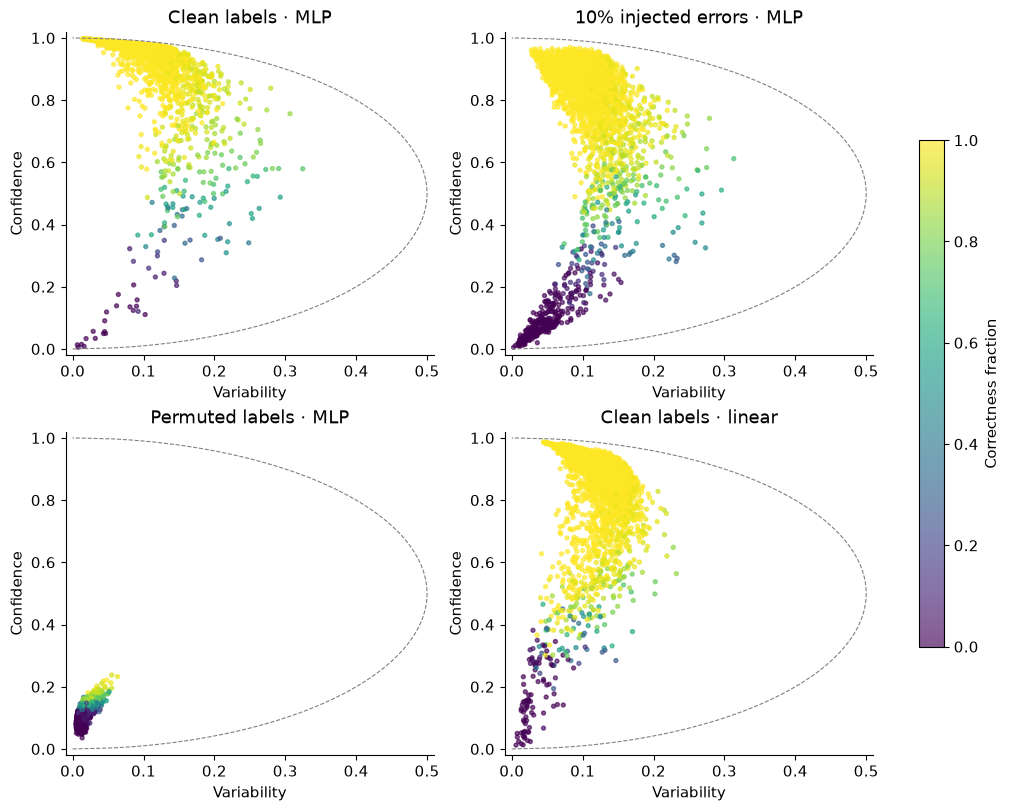

In [13]:
def draw_map(ax, stats, title, replicate=0):
    points = ax.scatter(
        stats["variability"][replicate],
        stats["confidence"][replicate],
        c=stats["correctness"][replicate],
        s=8,
        cmap="viridis",
        vmin=0,
        vmax=1,
        alpha=0.65,
        rasterized=True,
    )
    mean = torch.linspace(0, 1, 301)
    ax.plot(torch.sqrt(mean * (1 - mean)), mean, color="gray", lw=0.8, ls="--")
    ax.set(
        title=title,
        xlabel="Variability",
        ylabel="Confidence",
        xlim=(-0.01, 0.51),
        ylim=(-0.02, 1.02),
    )
    return points


fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
for ax, name, title in zip(
    axes.flat,
    ("clean", "noisy", "shuffled", "linear"),
    (
        "Clean labels · MLP",
        "10% injected errors · MLP",
        "Permuted labels · MLP",
        "Clean labels · linear",
    ),
):
    points = draw_map(ax, mapping["statistics"][name]["end"], title)
fig.colorbar(points, ax=axes, label="Correctness fraction", shrink=0.7)
show_figure(fig, "cartography_maps")


### Read a point before naming a region

At the upper left, the assigned label receives high probability throughout the
recorded window. At the lower left, it receives low probability throughout.
The right-hand region contains substantial change over time. That change can
include a smooth learning transition; it need not mean the image is ambiguous
to a human, or that the model oscillates between answers.

The shuffled-label map has a different interpretation from the clean-label map.
Its labels no longer provide a reliable digit-recognition target. A visually
structured map alone cannot establish that its regions are useful. Check the
training curves, then later its held-out predictions against original labels.
The linear comparison changes the learner while keeping data and optimizer
settings fixed.


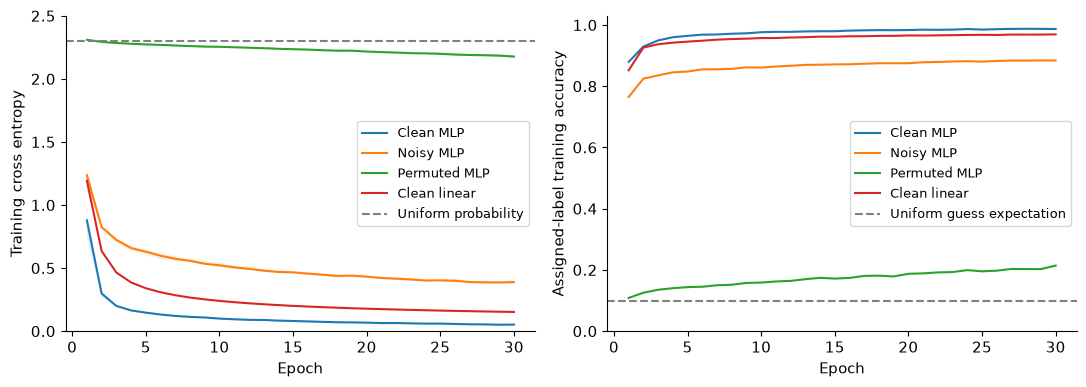

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, label in (
    ("clean", "Clean MLP"),
    ("noisy", "Noisy MLP"),
    ("shuffled", "Permuted MLP"),
    ("linear", "Clean linear"),
):
    loss = mapping["runs"][name]["loss"]
    axes[0].plot(range(1, 31), loss.mean(1), label=label)
    axes[0].fill_between(range(1, 31), loss.min(1).values, loss.max(1).values, alpha=0.12)
    correct = (
        (
            mapping["runs"][name]["end_logits"].argmax(-1)
            == train[
                {"clean": "y", "noisy": "noisy_y", "shuffled": "shuffled_y", "linear": "y"}[name]
            ]
        )
        .float()
        .mean(-1)
    )
    axes[1].plot(range(1, 31), correct.mean(1), label=label)
axes[0].axhline(math.log(10), color="gray", ls="--", label="Uniform probability")
axes[1].axhline(0.1, color="gray", ls="--", label="Uniform guess expectation")
axes[0].set(xlabel="Epoch", ylabel="Training cross entropy", ylim=(0, 2.5))
axes[1].set(xlabel="Epoch", ylabel="Assigned-label training accuracy", ylim=(0, 1.03))
axes[0].legend(fontsize=9)
axes[1].legend(fontsize=9)
fig.tight_layout()
show_figure(fig, "cartography_training")


### When was the measurement taken?

The next plots compare the two logging conventions for the same clean model.
Each point now represents one example measured twice. The identity line would
mean exact agreement. Then compare early, full and late training windows.
A repeated final checkpoint is the control: it contains no training history
and its variability is zero, even for an incorrectly classified image.


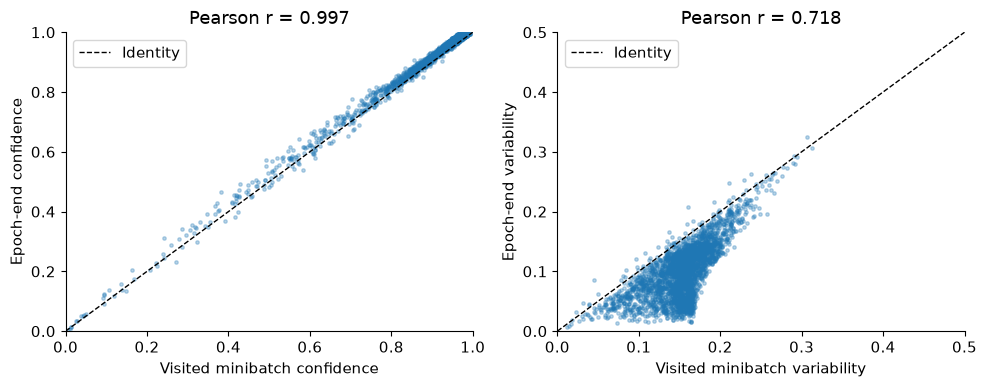

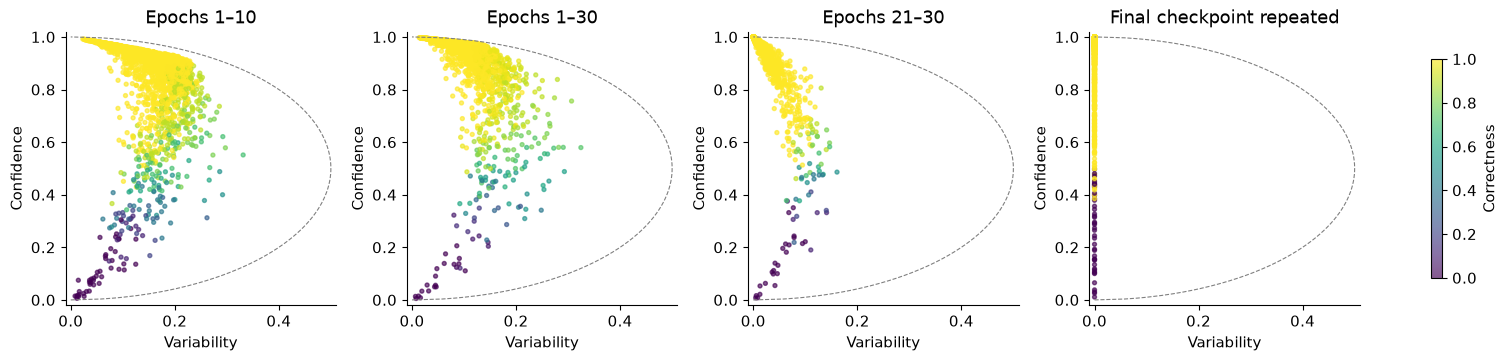

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ("confidence", "variability")):
    online = mapping["statistics"]["clean"]["online"][metric][0]
    end = mapping["statistics"]["clean"]["end"][metric][0]
    upper = 1 if metric == "confidence" else 0.5
    ax.scatter(online, end, s=6, alpha=0.3)
    ax.plot([0, upper], [0, upper], "k--", lw=1, label="Identity")
    correlation = float(torch.corrcoef(torch.stack([online, end]))[0, 1])
    ax.set(
        xlabel=f"Visited minibatch {metric}",
        ylabel=f"Epoch-end {metric}",
        title=f"Pearson r = {correlation:.3f}",
        xlim=(0, upper),
        ylim=(0, upper),
    )
    ax.legend()
fig.tight_layout()
show_figure(fig, "cartography_logging")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), constrained_layout=True)
for ax, stats, title in zip(
    axes,
    [
        mapping["windows"]["early"],
        mapping["statistics"]["clean"]["end"],
        mapping["windows"]["late"],
        mapping["windows"]["repeated_final"],
    ],
    ["Epochs 1–10", "Epochs 1–30", "Epochs 21–30", "Final checkpoint repeated"],
):
    points = draw_map(ax, stats, title)
fig.colorbar(points, ax=axes, label="Correctness", shrink=0.8)
show_figure(fig, "cartography_windows")


<details><summary>Interpretation - what changed most?</summary>

In the reference run, online and epoch-end confidence correlate at about 0.997,
but variability correlates at about 0.718. The first convention includes the
model before it has learned from many first-epoch minibatches. This need not
preserve a ranking based on temporal standard deviation.

The late-window map asks about a different part of learning. Its smaller
variability does not prove those examples were always easy. Keep the epoch
window with the map whenever reporting a result.

</details>

### How stable is the map across runs?

Correlation asks whether scores move together across all examples. Jaccard
asks whether two rankings actually choose the same retained set. High overall
correlation does not force the examples near a selection cutoff to agree.
The diagonal is the identical-run control; a random one-third set has expected
intersection near $N/9$, giving a large-$N$ Jaccard reference near $1/5$.


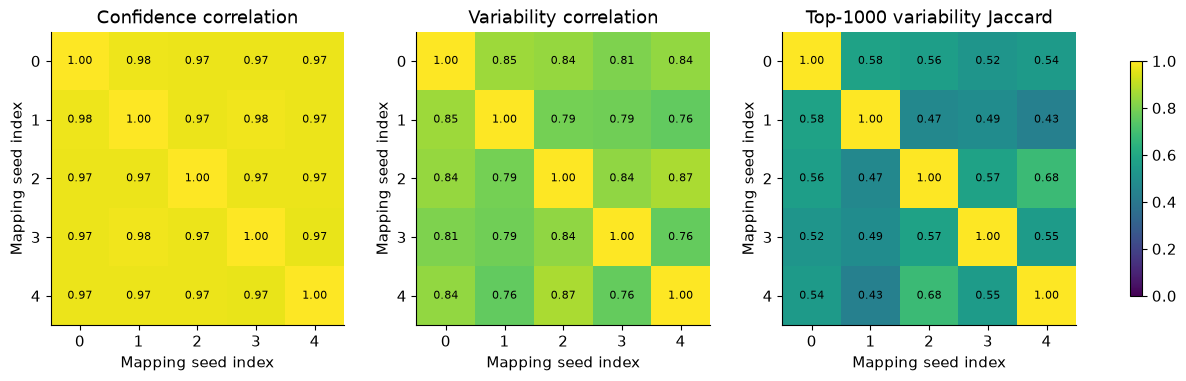

In [16]:
stats = mapping["statistics"]["clean"]["end"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), constrained_layout=True)
for ax, metric in zip(axes[:2], ("confidence", "variability")):
    matrix = torch.corrcoef(stats[metric])
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis")
    ax.set(
        title=f"{metric.title()} correlation",
        xlabel="Mapping seed index",
        ylabel="Mapping seed index",
    )
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8)
selected = [select_indices(row, 1000) for row in stats["variability"]]
jaccard = torch.stack([torch.stack([selection_overlap(a, b) for b in selected]) for a in selected])
axes[2].imshow(jaccard, vmin=0, vmax=1, cmap="viridis")
axes[2].set(
    title="Top-1000 variability Jaccard", xlabel="Mapping seed index", ylabel="Mapping seed index"
)
axes[2].set_xticks(range(5))
axes[2].set_yticks(range(5))
for i in range(5):
    for j in range(5):
        axes[2].text(j, i, f"{jaccard[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.8)
show_figure(fig, "cartography_seed_stability")


### Does a different measurement select the same data?

The next comparison changes one measurement choice while keeping the underlying
clean run paired by seed. Each cell averages five paired comparisons with the
full-window epoch-end map. Confidence/variability columns are Pearson
correlations; the remaining columns are top-1,000 set overlaps. The identical
measurement is a control with value one throughout. An undefined correlation
is left blank: a constant variability vector has no correlation coefficient.

The repeated-checkpoint variability ranking consists entirely of ties. Its
selected set therefore reflects our source-order tie rule, not a measured
learning difficulty. This is a useful example of a perfectly reproducible
selection that has no temporal information behind it.


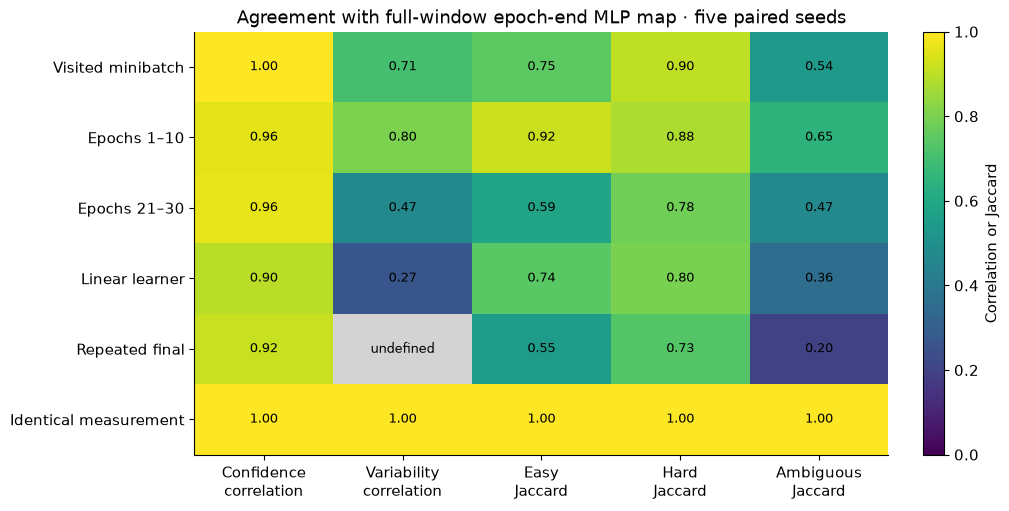

In [17]:
alternatives = {
    "Visited minibatch": mapping["statistics"]["clean"]["online"],
    "Epochs 1–10": mapping["windows"]["early"],
    "Epochs 21–30": mapping["windows"]["late"],
    "Linear learner": mapping["statistics"]["linear"]["end"],
    "Repeated final": mapping["windows"]["repeated_final"],
    "Identical measurement": stats,
}
comparison = []
for name, other in alternatives.items():
    rows = []
    for replicate in range(5):
        values = []
        for metric in ("confidence", "variability"):
            left, right = stats[metric][replicate], other[metric][replicate]
            values.append(
                float(torch.corrcoef(torch.stack([left, right]))[0, 1])
                if right.std() > 0
                else float("nan")
            )
        for metric, largest in (("confidence", True), ("confidence", False), ("variability", True)):
            left = select_indices(stats[metric][replicate], 1000, largest=largest)
            right = select_indices(other[metric][replicate], 1000, largest=largest)
            values.append(float(selection_overlap(left, right)))
        rows.append(values)
    comparison.append(torch.tensor(rows).mean(0))
comparison = torch.stack(comparison)
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
colormap = plt.colormaps["viridis"].copy()
colormap.set_bad("lightgray")
image = ax.imshow(comparison, vmin=0, vmax=1, cmap=colormap, aspect="auto")
ax.set_yticks(range(len(alternatives)), labels=list(alternatives))
ax.set_xticks(
    range(5),
    labels=[
        "Confidence\ncorrelation",
        "Variability\ncorrelation",
        "Easy\nJaccard",
        "Hard\nJaccard",
        "Ambiguous\nJaccard",
    ],
)
for i in range(len(alternatives)):
    for j in range(5):
        label = f"{comparison[i,j]:.2f}" if torch.isfinite(comparison[i, j]) else "undefined"
        ax.text(j, i, label, ha="center", va="center", fontsize=9)
ax.set_title("Agreement with full-window epoch-end MLP map · five paired seeds")
fig.colorbar(image, ax=ax, label="Correlation or Jaccard")
show_figure(fig, "cartography_measurement_stability")


### Find the images behind the coordinates

Inspect the first four images in each ranking. The fourth row is a fixed random
control. The next figure follows those same images across every epoch. Compare
a steady rise with an actual reversal, and compare assigned-label probability
with the maximum probability over classes. A disagreement between the two curves
means the model preferred a different label.

The top of a ranking is shown to help interpret the rule; it is not a random
sample of the entire retained set.


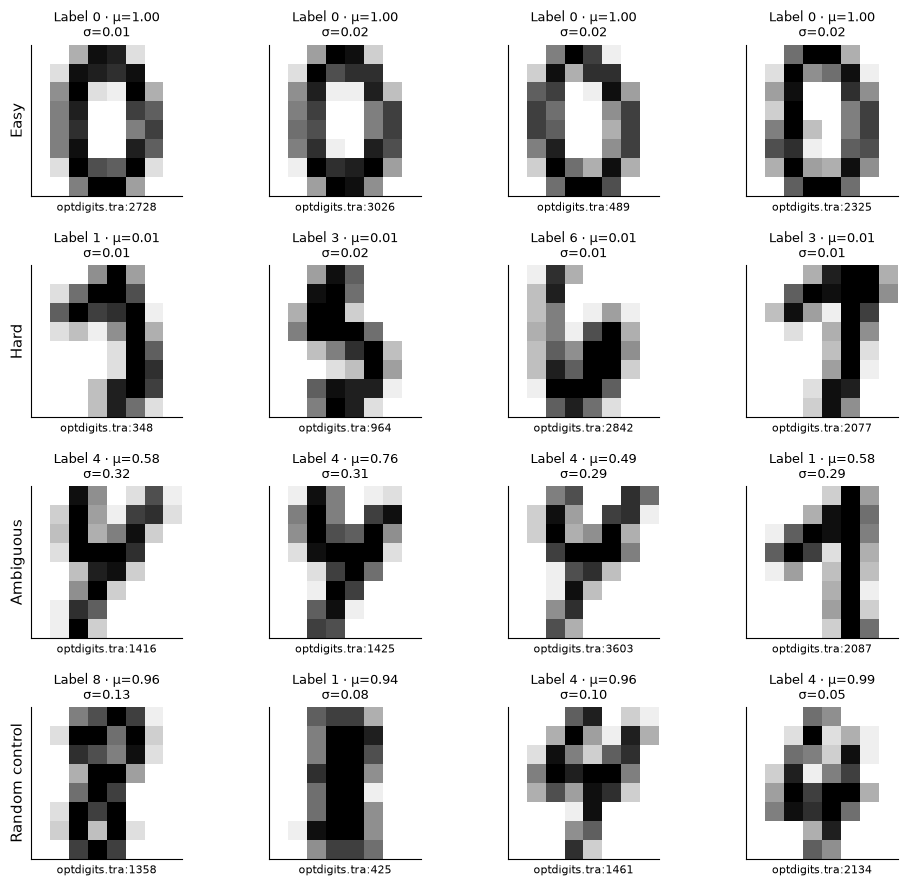

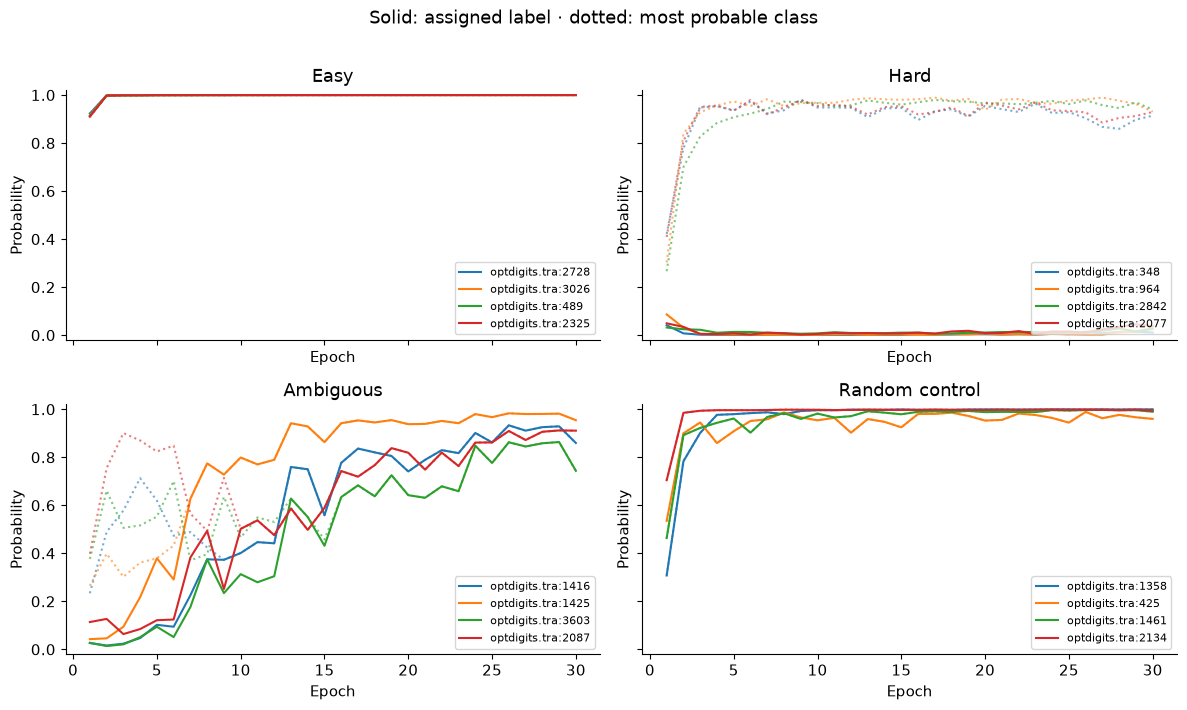

In [18]:
gallery = {
    "Easy": select_indices(stats["confidence"][0], 4),
    "Hard": select_indices(stats["confidence"][0], 4, largest=False),
    "Ambiguous": select_indices(stats["variability"][0], 4),
    "Random control": torch.randperm(3000, generator=torch.Generator().manual_seed(166200))[:4],
}
fig, axes = plt.subplots(4, 4, figsize=(10, 9))
for row, (region, indices) in enumerate(gallery.items()):
    for ax, index in zip(axes[row], indices):
        ax.imshow(train["x"][index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(
            f"Label {int(train['y'][index])} · μ={stats['confidence'][0,index]:.2f}\nσ={stats['variability'][0,index]:.2f}",
            fontsize=9,
        )
        ax.set_xlabel(train["ids"][index], fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(region, fontsize=11)
fig.tight_layout()
show_figure(fig, "cartography_region_gallery")

probabilities = gold_probabilities(mapping["runs"]["clean"]["end_logits"], train["y"].expand(5, -1))
top_probability = mapping["runs"]["clean"]["end_logits"].softmax(-1).max(-1).values
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, (region, indices) in zip(axes.flat, gallery.items()):
    for index in indices:
        (line,) = ax.plot(range(1, 31), probabilities[:, 0, index], label=train["ids"][index])
        ax.plot(
            range(1, 31), top_probability[:, 0, index], ls=":", color=line.get_color(), alpha=0.6
        )
    ax.set(title=region, xlabel="Epoch", ylabel="Probability", ylim=(-0.02, 1.02))
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Solid: assigned label · dotted: most probable class", y=1.01)
fig.tight_layout()
show_figure(fig, "cartography_region_trajectories")


### Diagnose the controlled errors

Each noisy model starts from the same initialization and uses the same example
order as its paired clean model. We rank by low confidence **in the changed
assigned label**. Compare against random inspection and the confidence ranking
from the uncorrupted training run. The latter asks whether the original digit
was already difficult before its label was changed.

The known injected-error mask is available only because we created the errors.
For naturally labeled data, low-confidence examples need inspection; a score
alone does not tell you whether the label, the image or the learner is at fault.


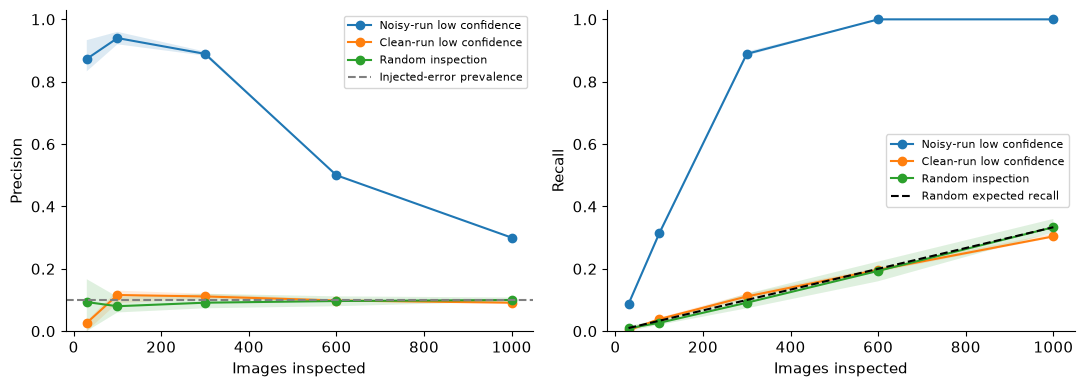

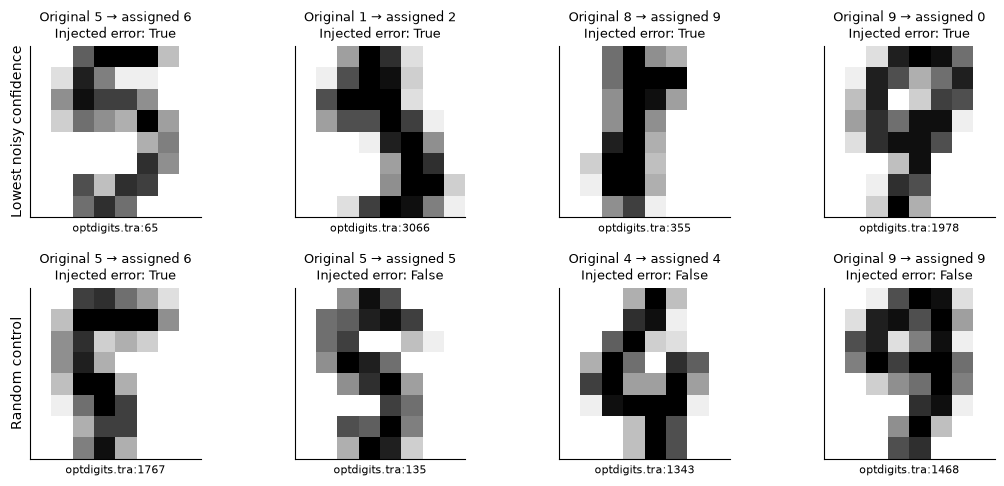

In [19]:
budgets = mapping["diagnosis_budgets"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for method, label in (
    ("noisy", "Noisy-run low confidence"),
    ("clean", "Clean-run low confidence"),
    ("random", "Random inspection"),
):
    for ax, metric in zip(axes, ("precision", "recall")):
        values = torch.stack([mapping["diagnosis"][str(i)][method][metric] for i in range(5)])
        ax.plot(budgets, values.mean(0), "o-", label=label)
        ax.fill_between(budgets, values.min(0).values, values.max(0).values, alpha=0.15)
        ax.set(xlabel="Images inspected", ylabel=metric.title(), ylim=(0, 1.03))
axes[0].axhline(0.1, color="gray", ls="--", label="Injected-error prevalence")
axes[1].plot(budgets, budgets / 3000, "k--", label="Random expected recall")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
show_figure(fig, "cartography_error_retrieval")

indices = select_indices(mapping["statistics"]["noisy"]["end"]["confidence"][0], 4, largest=False)
random = torch.randperm(3000, generator=torch.Generator().manual_seed(166201))[:4]
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for row, (title, chosen) in enumerate(
    (("Lowest noisy confidence", indices), ("Random control", random))
):
    for ax, index in zip(axes[row], chosen):
        ax.imshow(train["x"][index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(
            f"Original {int(train['y'][index])} → assigned {int(train['noisy_y'][index])}\nInjected error: {bool(train['changed'][index])}",
            fontsize=9,
        )
        ax.set_xlabel(train["ids"][index], fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(title, fontsize=10)
fig.tight_layout()
show_figure(fig, "cartography_noise_gallery")


<details><summary>Expected output and interpretation</summary>

At an inspection budget of 300, the five noisy-run rankings have precision
about 0.883–0.897. Since there are exactly 300 injected errors, recall has the
same numerical value at this particular budget. That equality would disappear
at a different budget. A random ranking has expected precision 0.1.

The misses and false positives matter. Neither a 300-image inspection budget
nor a low-confidence cutoff establishes that every retrieved example is wrong.
The untouched source labels are comparison labels, not a fresh human audit.

</details>

## 3️⃣ Does selecting a region help a new model?

A map is descriptive. A claim about which data to keep requires a new training
experiment. We fix the clean MLP map from seed 161100 before opening holdout
predictions. We retain 300, 1,000 or 2,000 examples by each region ranking and
train five fresh models for every selection.

A first complication is **class coverage**. Globally selecting high-confidence
examples can almost eliminate a class. Uniform random subsets control retained
size, but they do not reproduce that class imbalance. We therefore add random
subsets with exactly the selected set's label counts. These controls may share
examples with the selected set; disjointness would change the sampling question.

Mapping seeds are separate from retraining seeds. We retain all five results,
including failures; the best seed is never selected by a holdout score.


### Exercise - construct a class-matched random control

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10–15 minutes on this exercise.
> ```

Given observed labels, one selected index vector and a fresh seed, draw a
uniform random subset within each class with exactly the selected counts.
Return sorted canonical indices without replacement. The control uses observed
labels; it does not consult model scores or held-out performance.


In [ ]:
def matched_random_indices(labels: Tensor, selected: Tensor, seed: int) -> Tensor:
    """Uniform sampling within each observed class, matching selected label counts."""
    raise NotImplementedError()


tests.test_matched_random_indices(matched_random_indices)


<details>
<summary>Help - where should I start?</summary>

Count selected examples per label. Permute all candidates in that label with
a local generator, take the required number, and concatenate. Sorting the final
indices establishes the canonical order before the training loop shuffles them.

</details>

<details>
<summary>Expected output</summary>

A selection with class counts `[2, 3, 1]` yields a random control with exactly
those counts for every tested seed, with no duplicate examples.

</details>

<details><summary>Solution</summary>

```python
def matched_random_indices(labels: Tensor, selected: Tensor, seed: int) -> Tensor:
    """Uniform sampling within each observed class, matching selected label counts."""
    if selected.ndim != 1 or selected.unique().numel() != selected.numel():
        raise ValueError("Selected training indices must be a vector without duplicates.")
    generator = torch.Generator().manual_seed(seed)
    result = []
    for label in labels.unique(sorted=True):
        candidates = torch.where(labels == label)[0]
        count = int((labels[selected] == label).sum())
        order = torch.randperm(len(candidates), generator=generator)
        result.append(candidates[order[:count]])
    return torch.cat(result).sort().values
```

</details>


### Exercise - evaluate every held-out example

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10–15 minutes on this exercise.
> ```

Evaluate fixed parameter sets on a held-out input matrix. Return logits,
per-example correctness and cross entropy, average accuracy/loss and classwise
accuracy. This function must not train, choose a seed or select examples.
Classwise means assume each evaluated class is represented in the holdout.


In [ ]:
def evaluate_models(parameters: dict[str, Tensor], x: Tensor, labels: Tensor) -> dict[str, Tensor]:
    """One fixed holdout, evaluated for every model; no selection or fitting."""
    raise NotImplementedError()


tests.test_evaluate_models(evaluate_models)


<details>
<summary>Help - where should I start?</summary>

Expand the holdout along the model axis, run the forward function under
`no_grad`, and retain the per-example results before taking means. Cross entropy
uses the assigned true holdout labels, not the argmax predictions.

</details>

<details>
<summary>Expected output</summary>

Two fixture models obtain accuracies one and zero on exactly the same two
examples. Their losses match independent analytic logistic-loss values.

</details>

<details><summary>Solution</summary>

```python
def evaluate_models(parameters: dict[str, Tensor], x: Tensor, labels: Tensor) -> dict[str, Tensor]:
    """One fixed holdout, evaluated for every model; no selection or fitting."""
    models = len(next(iter(parameters.values())))
    with torch.no_grad():
        logits = batched_logits(parameters, x.expand(models, -1, -1))
        repeated_labels = labels.expand(models, -1)
        correct = logits.argmax(dim=-1) == repeated_labels
        losses = F.cross_entropy(
            logits.flatten(0, 1), repeated_labels.flatten(), reduction="none"
        ).reshape_as(repeated_labels)
        class_accuracy = torch.stack(
            [correct[:, labels == label].float().mean(dim=1) for label in range(logits.shape[-1])],
            dim=-1,
        )
    return dict(
        logits=logits,
        correct=correct,
        loss_per_example=losses,
        accuracy=correct.float().mean(dim=1),
        cross_entropy=losses.mean(dim=1),
        class_accuracy=class_accuracy,
    )
```

</details>


### Fix selections, train all models, then open the holdouts

The code below makes every selection first, then trains 120 new networks. At
each size it includes the three regions, three class-matched controls, and a
uniform random control. Five full-pool models provide a reference.

The final ten runs address optimizer budget. A 1,000-image subset gets eight
minibatches per epoch, versus 24 for the full pool. Training the ambiguous
subset and its matched random controls for 90 epochs gives them the same 720
updates as 30 full-pool epochs. This controls update count for this one
comparison; it is not a claim that all learning conditions are equivalent.

The complete selected sets and final parameters are saved before computing any
holdout model predictions. The save is a reproducibility aid; the plots below
are calculated from the actual models trained in these cells.


In [22]:
methods.matched_random_indices = matched_random_indices
methods.evaluate_models = evaluate_models


def make_selections(train, mapping, methods):
    stats = mapping["statistics"]["clean"]["end"]
    selections = {"full": torch.arange(len(train["y"])).expand(5, -1).clone()}
    for size_index, size in enumerate((300, 1000, 2000)):
        for region_index, region in enumerate(("easy", "hard", "ambiguous")):
            score = stats["variability" if region == "ambiguous" else "confidence"][0]
            selected = methods.select_indices(score, size, largest=region != "hard").sort().values
            name = f"{region}_{size}"
            selections[name] = selected.expand(5, -1).clone()
            selections[f"{name}_matched"] = torch.stack(
                [
                    methods.matched_random_indices(
                        train["y"],
                        selected,
                        161300 + 1000 * region_index + 10 * size_index + replicate,
                    )
                    for replicate in range(5)
                ]
            )
        selections[f"uniform_{size}"] = torch.stack(
            [
                torch.randperm(
                    len(train["y"]),
                    generator=torch.Generator().manual_seed(165000 + 10 * size_index + replicate),
                )[:size]
                .sort()
                .values
                for replicate in range(5)
            ]
        )
    return selections


def retrain_selections(train, mapping, methods, directory):
    selections = make_selections(train, mapping, methods)
    # Persist every selection before retraining, and retain all seeds afterwards.
    torch.save(selections, directory / "selections_before_refits.pt")
    fits = {}
    seeds = list(range(161200, 161205))
    for name, indices in selections.items():
        fits[name] = methods.train_ensemble(
            train["x"][indices], train["y"][indices], seeds, record=False
        )
    for source in ("ambiguous_1000", "ambiguous_1000_matched"):
        indices = selections[source]
        name = f"{source}_equal_updates"
        fits[name] = methods.train_ensemble(
            train["x"][indices], train["y"][indices], seeds, epochs=90, record=False
        )
        torch.testing.assert_close(fits[name]["loss"][:30], fits[source]["loss"], rtol=0, atol=0)
        selections[name] = indices.clone()
    result = dict(
        phase="ALL_SELECTIONS_AND_FRESH_TRAINING_COMPLETE",
        ids=train["ids"],
        selections=selections,
        fits=fits,
        heldout_predictions_computed=False,
        refits=sum(len(run["seeds"]) for run in fits.values()),
    )
    if result["refits"] != 120:
        raise ValueError("The complete selection study requires 120 fresh refits.")
    torch.save(result, directory / "prepared.pt")
    return result


prepared = retrain_selections(train, mapping, methods, native_directory)
boundary = {
    "phase": prepared["phase"],
    "heldout_predictions_computed": False,
    "mapping_sha256": hashlib.sha256((native_directory / "mapping.pt").read_bytes()).hexdigest(),
    "prepared_sha256": hashlib.sha256((native_directory / "prepared.pt").read_bytes()).hexdigest(),
}
(OUTPUT / "before_evaluation.json").write_text(json.dumps(boundary, indent=2) + "\n")
print("All selections and 120 fresh refits saved. Holdout predictions have not been computed.")


All selections and 120 fresh refits saved. Holdout predictions have not been computed.


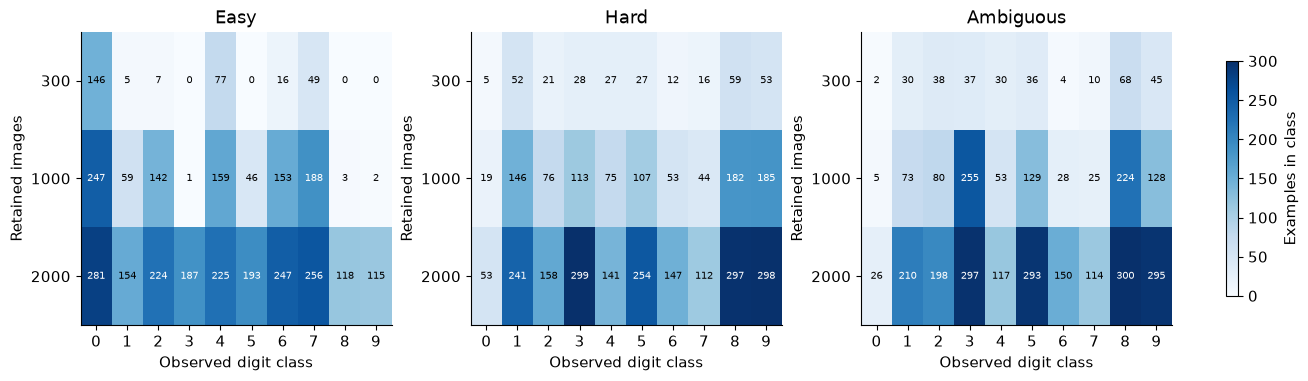

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), constrained_layout=True)
for ax, region in zip(axes, ("easy", "hard", "ambiguous")):
    counts = torch.stack(
        [
            torch.bincount(train["y"][prepared["selections"][f"{region}_{n}"][0]], minlength=10)
            for n in (300, 1000, 2000)
        ]
    )
    image = ax.imshow(counts, vmin=0, vmax=300, cmap="Blues", aspect="auto")
    ax.set(title=region.title(), xlabel="Observed digit class", ylabel="Retained images")
    ax.set_xticks(range(10))
    ax.set_yticks(range(3), labels=[300, 1000, 2000])
    for i in range(3):
        for j in range(10):
            ax.text(
                j,
                i,
                int(counts[i, j]),
                ha="center",
                va="center",
                fontsize=7,
                color="white" if counts[i, j] > 170 else "black",
            )
fig.colorbar(image, ax=axes, label="Examples in class", shrink=0.8)
show_figure(fig, "cartography_class_counts")


The easy 300-image selection contains **no examples of digits 3, 5, 8 or 9**
in the reference run. Its matched control has the same omissions. The one-third
ambiguous selection heavily favors some classes and contains only five zeros.
This is why a size-matched uniform control and a class-matched control answer
different questions. These counts come entirely from training data.


In [24]:
def evaluate_study(mapping, prepared, evaluation, methods, directory):
    if (
        prepared["phase"] != "ALL_SELECTIONS_AND_FRESH_TRAINING_COMPLETE"
        or prepared["heldout_predictions_computed"]
    ):
        raise ValueError("Save every selection and fresh training run before evaluating holdouts.")
    output = dict(
        holdout_ids={name: split["ids"] for name, split in evaluation.items()},
        mapping={},
        refits={},
    )
    for category, runs in (("mapping", mapping["runs"]), ("refits", prepared["fits"])):
        for name, run in runs.items():
            output[category][name] = {
                split_name: methods.evaluate_models(run["parameters"], split["x"], split["y"])
                for split_name, split in evaluation.items()
            }
    output["evaluated_models"] = 140
    output["evaluation_used_for_selection"] = False
    torch.save(output, directory / "evaluated.pt")
    return output


evaluation = load_evaluation()
evaluated = evaluate_study(mapping, prepared, evaluation, methods, native_directory)
print("Evaluated all 140 models on 823 same-source and 1797 separate-writer images.")


Evaluated all 140 models on 823 same-source and 1797 separate-writer images.


### Do the map controls generalize to original labels?

Here are the held-out results for the four mapping conditions, with all five
seeds visible. Holdout labels were never corrupted or shuffled. A shuffled-label
model can improve its training accuracy yet remain near chance on digit
recognition. This is the behavioral control behind the earlier map comparison.
The noisy model's loss of accuracy also shows that the injected errors were
not merely cosmetic changes to a scatter plot.


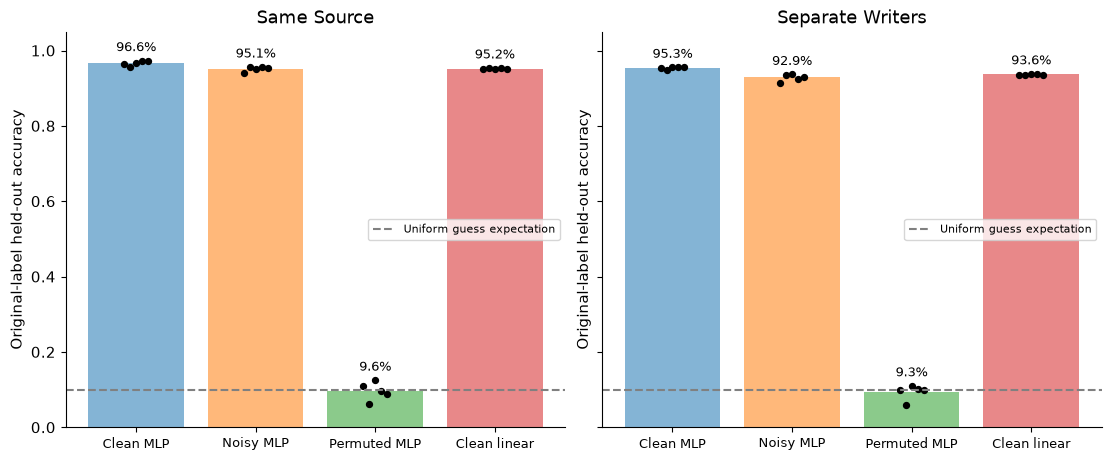

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, constrained_layout=True)
conditions = ("clean", "noisy", "shuffled", "linear")
for ax, split in zip(axes, ("same_source", "separate_writers")):
    for index, name in enumerate(conditions):
        values = evaluated["mapping"][name][split]["accuracy"]
        ax.bar(index, values.mean(), color=f"C{index}", alpha=0.55)
        ax.scatter(index + np.linspace(-0.1, 0.1, 5), values, color="black", s=18)
        ax.text(index, float(values.max()) + 0.025, f"{values.mean():.1%}", ha="center", fontsize=9)
    ax.axhline(0.1, color="gray", ls="--", label="Uniform guess expectation")
    ax.set_xticks(
        range(4), labels=["Clean MLP", "Noisy MLP", "Permuted MLP", "Clean linear"], fontsize=9
    )
    ax.set(
        title=split.replace("_", " ").title(),
        ylabel="Original-label held-out accuracy",
        ylim=(0, 1.05),
    )
    ax.legend(fontsize=8, loc="center right")
show_figure(fig, "cartography_mapping_generalization")


### Read all seeds, not just the winner

Each curve below shows the mean of five retraining runs, with the full range
shaded. This range describes these runs; it is not a confidence interval over
all possible datasets. For a fixed region, the selected set is shared across
seeds. Its matched controls also vary the sampled subset. Paired seeds share
initializations, but differing training inputs still change the optimization
path. The horizontal full-pool baseline uses all 3,000 images.

The second set of curves uses cross entropy. Accuracy can stay unchanged while
confidence on correct or incorrect predictions changes substantially.


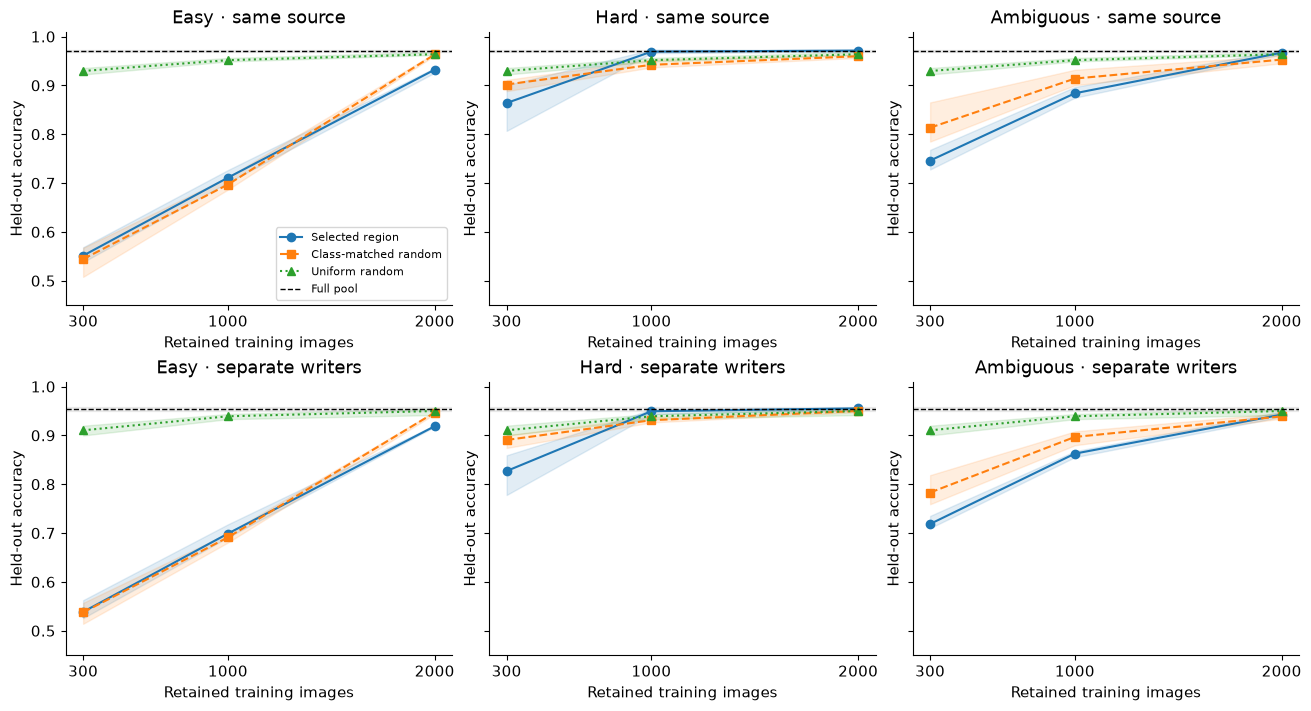

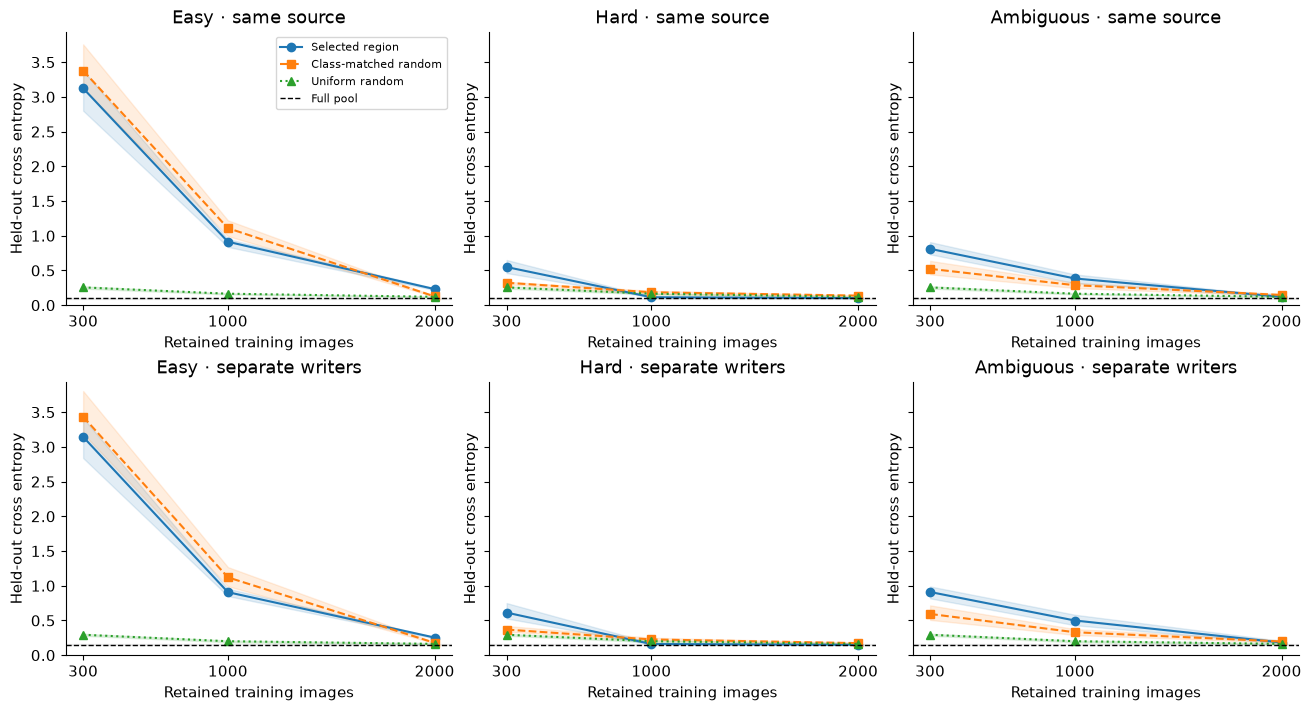

In [26]:
sizes = (300, 1000, 2000)
for metric, ylabel, filename in (
    ("accuracy", "Held-out accuracy", "cartography_selection_accuracy"),
    ("cross_entropy", "Held-out cross entropy", "cartography_selection_loss"),
):
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True, constrained_layout=True)
    for row, split in enumerate(("same_source", "separate_writers")):
        for col, region in enumerate(("easy", "hard", "ambiguous")):
            ax = axes[row, col]
            for kind, label, style in (
                (region, "Selected region", "o-"),
                (region + "_matched", "Class-matched random", "s--"),
                ("uniform", "Uniform random", "^:"),
            ):
                keys = [
                    f"{region}_{n}_matched" if kind.endswith("_matched") else f"{kind}_{n}"
                    for n in sizes
                ]
                values = torch.stack([evaluated["refits"][key][split][metric] for key in keys])
                (line,) = ax.plot(sizes, values.mean(1), style, label=label)
                ax.fill_between(
                    sizes,
                    values.min(1).values,
                    values.max(1).values,
                    alpha=0.13,
                    color=line.get_color(),
                )
            full = evaluated["refits"]["full"][split][metric]
            ax.axhline(float(full.mean()), color="black", ls="--", lw=1, label="Full pool")
            ax.axhspan(float(full.min()), float(full.max()), color="gray", alpha=0.12)
            ax.set(
                title=f"{region.title()} · {split.replace('_', ' ')}",
                xlabel="Retained training images",
                ylabel=ylabel,
            )
            ax.set_xticks(sizes)
            if metric == "accuracy":
                ax.set_ylim(0.45, 1.01)
            else:
                ax.set_ylim(bottom=0)
            if row == 0 and col == 0:
                ax.legend(fontsize=8)
    show_figure(fig, filename)


<details><summary>Interpretation - did ambiguity win?</summary>

At 1,000 retained images, the separate-writer accuracy averages about **86.3%**
for high variability, **89.7%** for its class-matched random control, and **93.9%**
for uniform random selection. Low-confidence selection averages about **95.0%**,
close to the full-pool mean of **95.4%**. The larger 2,000-image selections tell
a different story, so do not summarize the entire experiment with one budget.

The paper found high-variability subsets useful for its NLP tasks and challenge
sets. That is a result to investigate, not a theorem about every dataset and
learner. This experiment uses a small digit network and a source-provided writer
split. It does not reproduce the paper's RoBERTa or natural-language OOD results.
Our own trajectories and class counts offer concrete reasons to be cautious
about transferring the word “ambiguous” across experiments.

</details>

### Does equalizing update count rescue the selection?

Compare the one-third ambiguous selection at 240 and 720 optimizer updates.
The matched random subsets get exactly the same two budgets. The full-pool
baseline has 720 updates. Longer training helps both one-third groups in this
run, but it does not reverse their ordering.


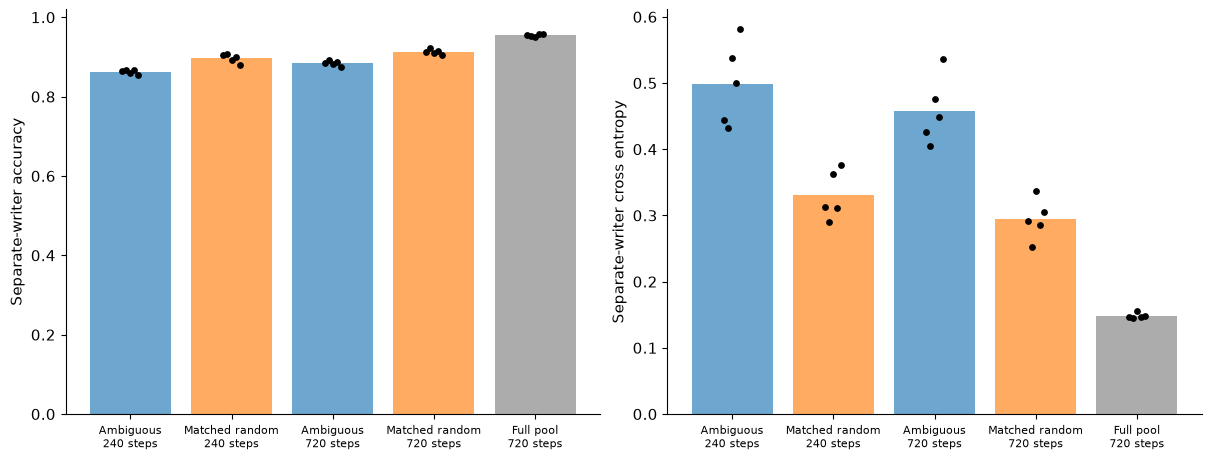

In [27]:
keys = [
    "ambiguous_1000",
    "ambiguous_1000_matched",
    "ambiguous_1000_equal_updates",
    "ambiguous_1000_matched_equal_updates",
    "full",
]
labels = [
    "Ambiguous\n240 steps",
    "Matched random\n240 steps",
    "Ambiguous\n720 steps",
    "Matched random\n720 steps",
    "Full pool\n720 steps",
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, metric, ylabel in zip(
    axes,
    ("accuracy", "cross_entropy"),
    ("Separate-writer accuracy", "Separate-writer cross entropy"),
):
    values = torch.stack([evaluated["refits"][key]["separate_writers"][metric] for key in keys])
    ax.bar(range(5), values.mean(1), color=["C0", "C1", "C0", "C1", "gray"], alpha=0.65)
    for seed in range(5):
        ax.scatter(np.arange(5) + (seed - 2) * 0.04, values[:, seed], color="black", s=15)
    ax.set_xticks(range(5), labels=labels, fontsize=8)
    ax.set_ylabel(ylabel)
    if metric == "accuracy":
        ax.set_ylim(0, 1.02)
    else:
        ax.set_ylim(bottom=0)
show_figure(fig, "cartography_equal_updates")


### Which classes and examples changed?

An average can hide a class that has nearly disappeared from the training set.
The first heatmap compares per-class accuracy for the one-third selections and
controls. The second figure pairs each selected model with the corresponding
full-pool seed and counts held-out examples that were gained or lost. A gain
means selected-only correct; a loss means full-pool-only correct. Shared errors
are excluded, so the two counts need not sum to the test-set size.


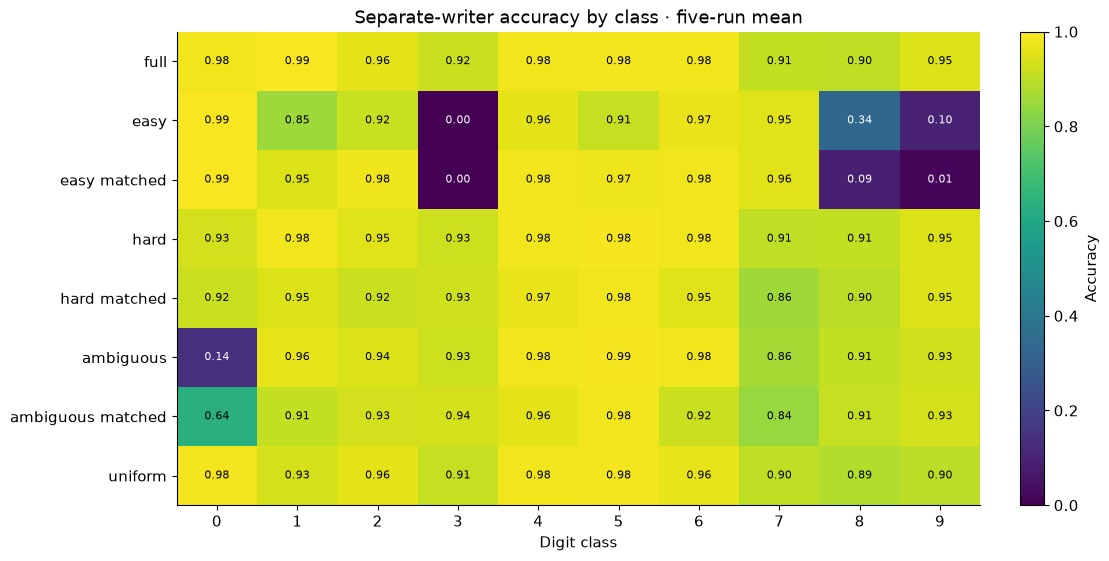

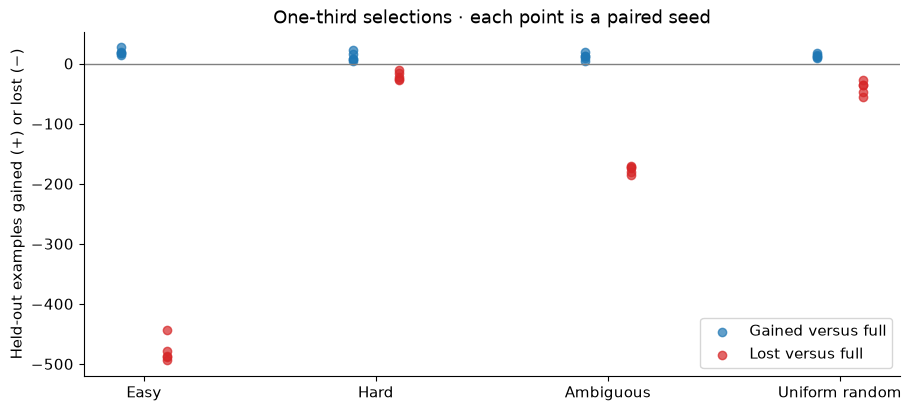

In [28]:
keys = [
    "full",
    "easy_1000",
    "easy_1000_matched",
    "hard_1000",
    "hard_1000_matched",
    "ambiguous_1000",
    "ambiguous_1000_matched",
    "uniform_1000",
]
values = torch.stack(
    [evaluated["refits"][key]["separate_writers"]["class_accuracy"].mean(0) for key in keys]
)
fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
image = ax.imshow(values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(10))
ax.set_yticks(range(len(keys)), labels=[k.replace("_1000", "").replace("_", " ") for k in keys])
ax.set(xlabel="Digit class", title="Separate-writer accuracy by class · five-run mean")
for i in range(len(keys)):
    for j in range(10):
        ax.text(
            j,
            i,
            f"{values[i,j]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if values[i, j] < 0.6 else "black",
        )
fig.colorbar(image, ax=ax, label="Accuracy")
show_figure(fig, "cartography_class_accuracy")

fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
full_correct = evaluated["refits"]["full"]["separate_writers"]["correct"]
for j, name in enumerate(("easy", "hard", "ambiguous", "uniform")):
    correct = evaluated["refits"][f"{name}_1000"]["separate_writers"]["correct"]
    gains = (correct & ~full_correct).sum(1)
    losses = (~correct & full_correct).sum(1)
    ax.scatter(
        torch.full((5,), j - 0.1),
        gains,
        color="C0",
        alpha=0.7,
        label="Gained versus full" if j == 0 else None,
    )
    ax.scatter(
        torch.full((5,), j + 0.1),
        -losses,
        color="C3",
        alpha=0.7,
        label="Lost versus full" if j == 0 else None,
    )
ax.axhline(0, color="gray", lw=1)
ax.set_xticks(range(4), labels=["Easy", "Hard", "Ambiguous", "Uniform random"])
ax.set(
    ylabel="Held-out examples gained (+) or lost (−)",
    title="One-third selections · each point is a paired seed",
)
ax.legend()
show_figure(fig, "cartography_paired_changes")


### Try It Yourself - choose a region and actually retrain

Change `region`, `retained`, `seed` or `epochs` below. Before running, inspect
the selected class counts and predict which classes will suffer. The cell trains
two fresh networks: your selection and a newly sampled class-matched random
control, using the same initialization seed. No trained weights are reused.

Use 90 epochs at 1,000 retained examples to repeat the equal-update question.
These experiments reuse the holdouts after we have already inspected results,
so treat new choices as exploration. Do not silently promote your favorite play
setting into the frozen experiment above.


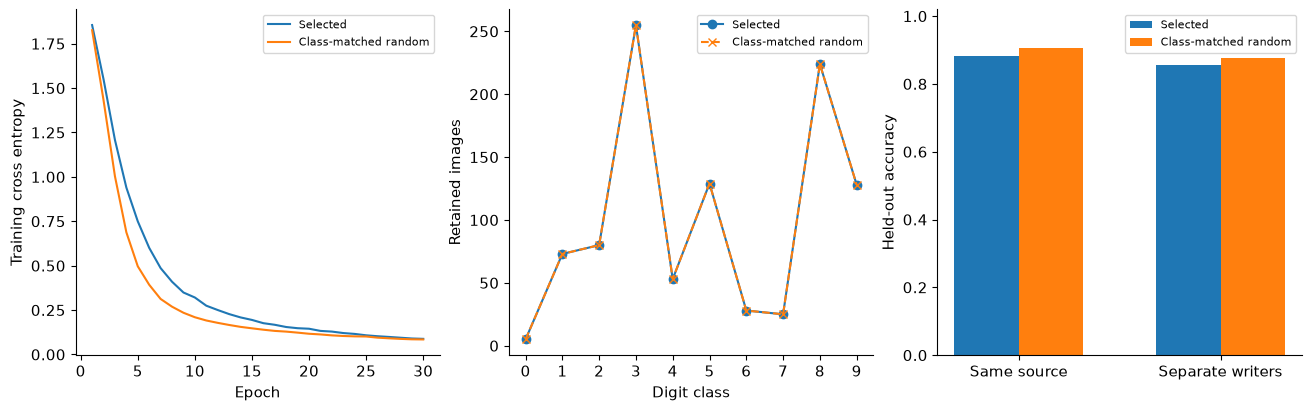

In [29]:
def retraining_play(
    train, mapping, evaluation, methods, region="ambiguous", size=1000, seed=166000, epochs=30
):
    if region not in ("easy", "hard", "ambiguous"):
        raise ValueError("Choose easy, hard or ambiguous.")
    stats = mapping["statistics"]["clean"]["end"]
    score = stats["variability" if region == "ambiguous" else "confidence"][0]
    selected = methods.select_indices(score, size, largest=region != "hard").sort().values
    random = methods.matched_random_indices(train["y"], selected, seed + 1)
    indices = torch.stack([selected, random])
    run = methods.train_ensemble(
        train["x"][indices], train["y"][indices], [seed, seed], epochs=epochs, record=False
    )
    return dict(
        region=region,
        indices=indices,
        run=run,
        evaluation={
            name: methods.evaluate_models(run["parameters"], split["x"], split["y"])
            for name, split in evaluation.items()
        },
        exploratory_holdout_reuse=True,
    )


region = "ambiguous"
retained = 1000
seed = 166000
epochs = 30
play = retraining_play(train, mapping, evaluation, methods, region, retained, seed, epochs)
torch.save(play, native_directory / "play.pt")
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for index, label in enumerate(("Selected", "Class-matched random")):
    axes[0].plot(range(1, epochs + 1), play["run"]["loss"][:, index], label=label)
    counts = torch.bincount(train["y"][play["indices"][index]], minlength=10)
    axes[1].plot(range(10), counts, "o-" if index == 0 else "x--", label=label)
    results = [
        float(play["evaluation"][name]["accuracy"][index])
        for name in ("same_source", "separate_writers")
    ]
    axes[2].bar(np.arange(2) + (index - 0.5) * 0.32, results, width=0.32, label=label)
axes[0].set(xlabel="Epoch", ylabel="Training cross entropy")
axes[1].set(xlabel="Digit class", ylabel="Retained images")
axes[1].set_xticks(range(10))
axes[2].set_xticks(range(2), labels=["Same source", "Separate writers"])
axes[2].set(ylabel="Held-out accuracy", ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8)
show_figure(fig, "cartography_real_play")


## What did the map tell us?

You implemented the coordinates, a training loop that records both logging
conventions, a controlled noise-diagnosis experiment, and actual retraining from
selected data. The result separates three questions that can otherwise blur
together: whether an example is learned late, whether its label is wrong, and
whether keeping it improves a new model.

Confidence was fairly stable across mapping seeds here, while variability and
selection membership were less stable. Low confidence found many injected label
errors, yet it also selected useful clean training examples. High variability
was not a universal best-subset rule. Class coverage and optimizer-update count
both mattered, and neither alone explained every difference.

### Limitations and further research

- The MLP and linear model are small digit classifiers. The separate-writer
  split tests a particular source-defined generalization setting, not the paper's
  independently collected language challenge sets.
- Noise is a fixed cyclic 10% corruption with known original labels. Real label
  ambiguity, systematic annotation conventions and naturally occurring errors
  require a separate audit; the detector's measured precision does not transfer
  automatically.
- There are five fixed mapping seeds and five retraining seeds. Selection uses
  one prescribed map. The result does not average across independent datasets,
  mapping-seed choices or alternative optimizers.
- The primary comparisons fix epochs. The 720-update control covers only the
  one-third ambiguous subset and its matched random controls. Mapping itself
  also costs a full training run; pruning does not make this initial cost vanish.
- A map loses temporal order and depends on the probability scale. It is not an
  estimate of an example's causal contribution, a posterior uncertainty measure,
  or evidence that an input is inherently easy or ambiguous.

For deeper self-study, explain why permuting epochs leaves every coordinate
unchanged but may change a forgetting count. Compare the same top-1,000 region
across all five mapping seeds. Design a class-stratified selection rule, fix its
budget and training schedule in advance, then reserve new evaluation data before
claiming an improvement. Identify which assumptions would have to change to
apply this notebook to fine-tuning a language model.

## Reading

- Swayamdipta et al. (2020), [Dataset Cartography: Mapping and Diagnosing Datasets
  with Training Dynamics](https://aclanthology.org/2020.emnlp-main.746/): start
  with Sections 2–3, then the noise experiment and Appendix A.1. Compare its
  model, task and evaluation setting with the claims supported here.
- [Authors' implementation](https://github.com/allenai/cartography): inspect
  `cartography/classification/run_glue.py` for the logging time and
  `cartography/selection/train_dy_filtering.py` for population variability.
  The code stores correctness as a count; our displayed fraction divides by epochs.
- [UCI Optical Recognition of Handwritten Digits](https://doi.org/10.24432/C50P49),
  Alpaydin and Kaynak (1998), CC BY 4.0. The frozen source manifest records every
  selected row and checksum.

### Optional reproducibility checks

The following cell repeats two full mapping runs separately and compares all
of their snapshots and final parameters with the scheduled runs. An independent
NumPy calculation checks the real-data coordinates. The earlier learner test
also compared your training loop with ordinary `torch.nn` and `torch.optim.SGD`.
These checks support the figures; they are not a substitute for interpreting them.


In [30]:
checks = reference_checks(train, mapping, methods)
(OUTPUT / "reference_checks.json").write_text(json.dumps(checks, indent=2) + "\n")
summary = summarize(mapping, prepared, evaluated, play, native_directory)
(OUTPUT / "native_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Separate full training and independent NumPy coordinate checks passed.")
print(
    f"Frozen experiment: {summary['main_training_runs']} real training runs, {summary['main_optimizer_updates']} optimizer updates, plus two separate checks and two play fits."
)


Separate full training and independent NumPy coordinate checks passed.
Frozen experiment: 140 real training runs, 53550 optimizer updates, plus two separate checks and two play fits.
